In [1]:
import sys
import matplotlib.pyplot as plt
plt.rc("axes.spines", top=False, right=False)

import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats

from scipy.stats import norm
from scipy.optimize import curve_fit

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
%load_ext autoreload
%autoreload 2

###can also use dir() to check what is in function and that new params have been loaded

import os
import glob


#desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
plot_path="../output/plots"
mypath = plot_path
import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc, summary_compt, avgCDF
from plots import plot_dsc

In [2]:
from pathlib import Path
DGdata={}

DGdata['branch1'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2016_07_07/branch1/tables/2016_07_07_slice4_left_branch1_Local Diameter.csv'}
DGdata['branch1']['file']= '2016_07_07_slice4_left_branch1_Local Diameter.csv'
DGdata['branch1']['ex_factor'] = 4.1
DGdata['branch1']['res'] = 1

#sub-branch of branch 3 
# DGdata['branch2'] = {'path':''M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2016_07_07/branch2/tables/2016_07_07_slice4_left_branch2_Local Diameter.csv'}
# DGdata['branch2']['file']= '2016_07_07_slice4_left_branch2_Local Diameter.csv'
# DGdata['branch2']['ex_factor'] = 4.1
# DGdata['branch2']['res'] = 1

DGdata['branch3'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2016_07_07/branch3/tables/2016_07_07_slice4_left_branch3_Local Diameter.csv'}
DGdata['branch3']['file']= 'branch3_comp_localDiameter1.csv'
DGdata['branch3']['ex_factor'] = 4.1
DGdata['branch3']['res'] = 1

DGdata['branch4'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2019_05_04/branch4/tables/2019_05_04_slice3_side1_branch4_localDiameter.csv'}
DGdata['branch4']['file']= '2019_05_04_slice3_side1_branch4_localDiameter.csv'
DGdata['branch4']['ex_factor'] = 4.1
DGdata['branch4']['res'] = 1

DGdata['C1_02_cell1_d2'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2020_06_08/T1_02/tables/20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv'}
DGdata['C1_02_cell1_d2']['file']= '20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv'
DGdata['C1_02_cell1_d2']['ex_factor'] = 3.8
DGdata['C1_02_cell1_d2']['res'] = 0.173

DGdata['C1_03_cell2_d2'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2020_06_08/T1_03/tables/20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend2 - Local Diameter.csv'}
DGdata['C1_03_cell2_d2']['file']= '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend2 - Local Diameter.csv'
DGdata['C1_03_cell2_d2']['ex_factor'] = 3.8
DGdata['C1_03_cell2_d2']['res'] = 0.173

DGdata['C1_03_cell2_d3']={'path' : 'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2020_06_08/T1_03/tables/20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend3 - Local Diameter.csv'}
DGdata['C1_03_cell2_d3']['file']= '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend3 - Local Diameter.csv'
DGdata['C1_03_cell2_d3']['ex_factor'] = 3.8
DGdata['C1_03_cell2_d3']['res'] = 0.173

In [ ]:
dataSet=DGdata
for name, dendrite in tqdm(dataSet.items()):
    #print(name)
    #print(data[name]['path'])
    
    file_path = dendrite['path']#+dendrite['file']
    dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

manually add DSC
    - DSC missing as diam increses slighlty in the middle

In [4]:
branch = DGdata['C1_03_cell2_d3']
DSC=branch['data'][3947:4047].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 

update_DSCs(branch)
update_compartments(branch)

In [ ]:
fig, ax = plot_dsc(DGdata['C1_03_cell2_d3'],'C1_03_cell2_d3', corr=1)

In [ ]:
ax.set_xlim(50, 320)
fig

Fig1 
Fig1g DSC mean diameter
Fig1h DSC lenght
Fig1j DSC distance

In [ ]:
#select property to plot [mean, lenght, distance]
parameter='distance'
df= summary_dsc(DGdata, parameter)

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("DSC_"+parameter)
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')

#ax.set_xlim([0,500])


Fig 1j Compartment length

In [ ]:
df= summary_compt(DGdata, 'length')

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("Compartment_length")
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')

ax.set_xlim([0,50])

Select branch and analyse

In [ ]:
x=130
end=320
res=DGdata['C1_03_cell2_d3']['res']
ex_factor=DGdata['C1_03_cell2_d3']['ex_factor']

DGdata['C1_03_cell2_d3']['branch']=DGdata['C1_03_cell2_d3']['data'][(DGdata['C1_03_cell2_d3']['data']['length'] < end*ex_factor/res) & (DGdata['C1_03_cell2_d3']['data']['length'] > x*ex_factor/res)]
#correct scaling
DGdata['C1_03_cell2_d3']['branch']['diam']=DGdata['C1_03_cell2_d3']['branch']['diam']/ex_factor
DGdata['C1_03_cell2_d3']['branch']['smth']=DGdata['C1_03_cell2_d3']['branch']['smth']/ex_factor

DGdata['C1_03_cell2_d3']['branch']['length']=DGdata['C1_03_cell2_d3']['branch']['length']/ex_factor*res

df=DGdata['C1_03_cell2_d3']['branch']
fig, ax = plt.subplots()
ax.plot(df.length, df.smth)
ax.set_ylim(100, 1400)
fig


df['smth'].median()

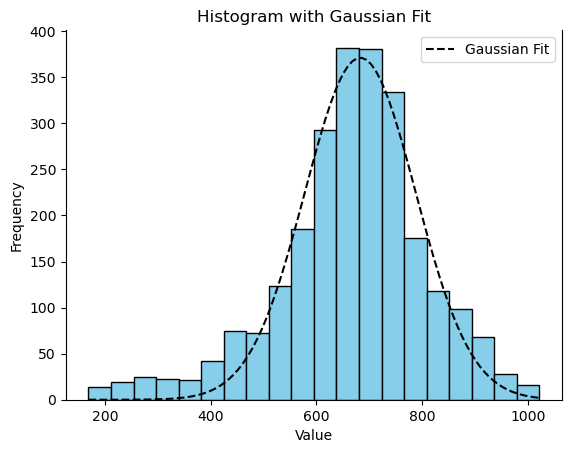

In [16]:
# Plot histogram
hist, bins, _ = plt.hist(DGdata['C1_03_cell2_d3']['branch']['smth'], bins=20, color='skyblue', edgecolor='black')

# Bin centers
bin_centers = 0.5 * (bins[1:] + bins[:-1])

# Fit Gaussian to histogram
def gaussian(x, mu, sigma, A):
    return A * np.exp(-0.5 * ((x - mu) / sigma)**2)

popt, _ = curve_fit(gaussian, bin_centers, hist, p0=[DGdata['C1_03_cell2_d3']['branch']['smth'].mean(), DGdata['C1_03_cell2_d3']['branch']['smth'].std(), 1])

# Plot Gaussian fit
x = np.linspace(DGdata['C1_03_cell2_d3']['branch']['smth'].min(), DGdata['C1_03_cell2_d3']['branch']['smth'].max(), 100)
plt.plot(x, gaussian(x, *popt), 'k--', label='Gaussian Fit')

# Add labels and title
plt.title('Histogram with Gaussian Fit')
plt.xlabel('Value')
plt.ylabel('Frequency')

# Show plot
plt.legend()
plt.show()

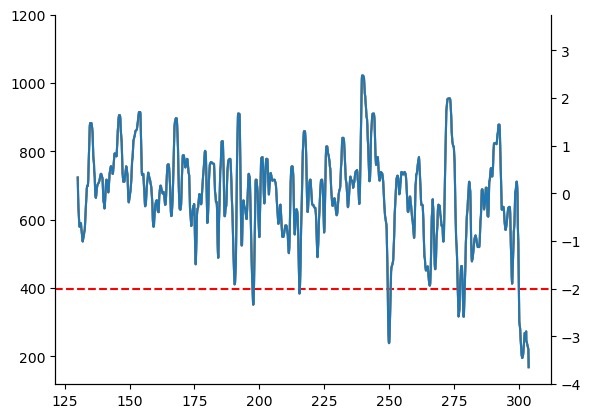

In [13]:
df=DGdata['C1_03_cell2_d3']['branch']
m=df['smth'].median()
std = df['smth'].std()

fig, ax1 = plt.subplots()

ax1.plot(df.length, df.smth)

# Add a straight line at a certain y-value
plt.axhline(y=m-(2*std), color='r', linestyle='--', label='Threshold')
ax1.set_ylim(df.smth.min()-50, 1200)

df_zscored = (df['smth'] - m) / std

#fig, ax1 = plt.subplots()

ax2 = ax1.twinx()
ax1.plot(df.length, df.smth) 
plt.rc("axes.spines", top=False, right=True)
ax2.plot(df.length, df_zscored) 
ax2.set_ylim((ax1.get_ylim()[0] - m) / std, (ax1.get_ylim()[1] - m) / std)

fig.savefig(plot_path +'/C1_branch_d3_zscore.svg', bbox_inches = 'tight', format='svg')
